# Web Analytics - Week 7 Assignment: Bipartite Network Analysis
## U.S. Congress Cosponsorship Network: Legislators x Bills

**Dataset:** Synthetic U.S. Congressional cosponsorship network (200 legislators, 150 bills)  
**Network type:** 2-mode bipartite (legislators co-sign legislation)  
**Reduction method:** Island method (threshold on edge weights in projected network)  
**Author:** Tanvir Raju



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx
from networkx.algorithms import bipartite
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
print("Libraries loaded.")

Libraries loaded.


## Part 1: Construct the Bipartite Network

In [2]:
# Generate realistic Congress cosponsorship network
np.random.seed(42)

n_dem = 110   # Democratic legislators
n_rep = 90    # Republican legislators
n_bills = 150 # Bills

# Legislator names (synthetic)
dem_names = [f"D-Rep{i:03d}" for i in range(1, n_dem + 1)]
rep_names = [f"R-Rep{i:03d}" for i in range(1, n_rep + 1)]
legislators = dem_names + rep_names

# Bills categorised by policy domain
domains = ["Healthcare", "Defense", "Education", "Economy", "Environment", "Immigration"]
bill_domains = np.random.choice(domains, size=n_bills,
                                p=[0.20, 0.18, 0.17, 0.18, 0.15, 0.12])
bills = [f"Bill{i:03d}_{bill_domains[i][:3].upper()}" for i in range(n_bills)]

# Build bipartite graph
G = nx.Graph()
G.add_nodes_from(legislators, bipartite=0, party="Democrat" if True else "Republican")
for name in dem_names:
    G.nodes[name]["party"] = "Democrat"
for name in rep_names:
    G.nodes[name]["party"] = "Republican"

G.add_nodes_from(bills, bipartite=1)
for i, bill in enumerate(bills):
    G.nodes[bill]["domain"] = bill_domains[i]

# Add edges: Democrats cosponsor healthcare/education/environment more
# Republicans cosponsor defense/economy/immigration more
for bill_idx, bill in enumerate(bills):
    domain = bill_domains[bill_idx]

    if domain in ["Healthcare", "Education", "Environment"]:
        # Dem-leaning bill: ~60% of Dems, ~15% of Reps cosponsor
        dem_cos = np.random.choice(dem_names, size=int(n_dem * np.random.uniform(0.35, 0.65)), replace=False)
        rep_cos = np.random.choice(rep_names, size=int(n_rep * np.random.uniform(0.05, 0.20)), replace=False)
    elif domain in ["Defense", "Economy", "Immigration"]:
        # Rep-leaning bill: ~15% of Dems, ~60% of Reps cosponsor
        dem_cos = np.random.choice(dem_names, size=int(n_dem * np.random.uniform(0.05, 0.20)), replace=False)
        rep_cos = np.random.choice(rep_names, size=int(n_rep * np.random.uniform(0.35, 0.65)), replace=False)
    else:
        dem_cos = np.random.choice(dem_names, size=int(n_dem * 0.30), replace=False)
        rep_cos = np.random.choice(rep_names, size=int(n_rep * 0.30), replace=False)

    for leg in list(dem_cos) + list(rep_cos):
        G.add_edge(leg, bill)

print(f"Bipartite graph constructed:")
print(f"  Legislators (group 0) : {len(legislators)} ({n_dem} Democrats, {n_rep} Republicans)")
print(f"  Bills (group 1)       : {len(bills)}")
print(f"  Total edges           : {G.number_of_edges()} (cosponsorship ties)")
print(f"  Is bipartite          : {bipartite.is_bipartite(G)}")
print(f"  Avg degree (legislators): {np.mean([G.degree(l) for l in legislators]):.2f} bills/legislator")
print(f"  Avg degree (bills)    : {np.mean([G.degree(b) for b in bills]):.2f} legislators/bill")

Bipartite graph constructed:
  Legislators (group 0) : 200 (110 Democrats, 90 Republicans)
  Bills (group 1)       : 150
  Total edges           : 9359 (cosponsorship ties)
  Is bipartite          : True
  Avg degree (legislators): 46.80 bills/legislator
  Avg degree (bills)    : 62.39 legislators/bill


## Part 2: Visualize the Full Bipartite Network

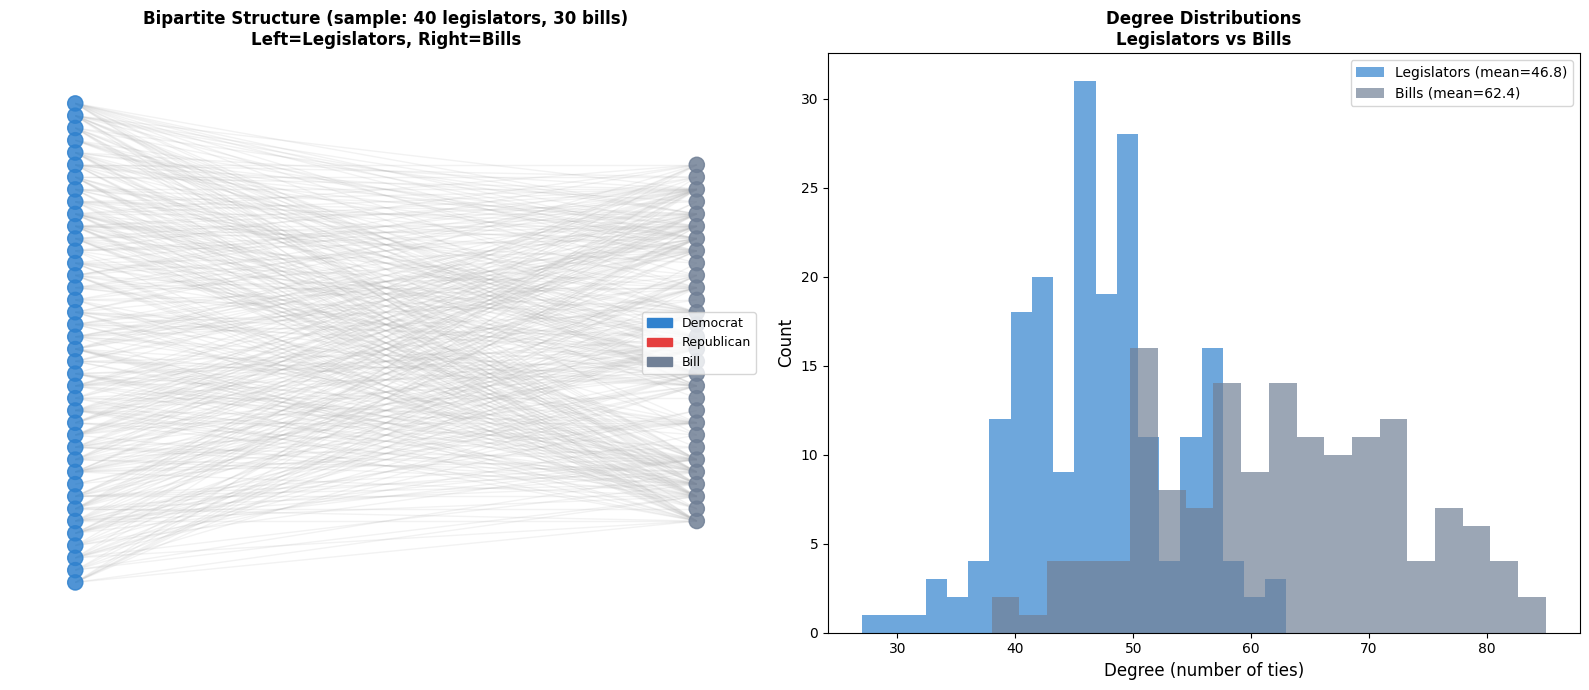

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- Left: bipartite layout sample (first 40 legislators, 30 bills for clarity) ---
sample_legs = legislators[:40]
sample_bills = bills[:30]
subG = G.subgraph(sample_legs + sample_bills).copy()

pos = {}
for i, l in enumerate(sample_legs):
    pos[l] = (0, len(sample_legs) - i)
for i, b in enumerate(sample_bills):
    pos[b] = (3, len(sample_bills) - i + 5)

node_colors = []
for n in subG.nodes():
    if n in sample_legs:
        node_colors.append("#3182CE" if G.nodes[n]["party"] == "Democrat" else "#E53E3E")
    else:
        node_colors.append("#718096")

nx.draw_networkx_nodes(subG, pos, node_color=node_colors, node_size=120, alpha=0.85, ax=axes[0])
nx.draw_networkx_edges(subG, pos, alpha=0.15, edge_color="#AAAAAA", ax=axes[0])

dem_patch = mpatches.Patch(color="#3182CE", label="Democrat")
rep_patch = mpatches.Patch(color="#E53E3E", label="Republican")
bill_patch = mpatches.Patch(color="#718096", label="Bill")
axes[0].legend(handles=[dem_patch, rep_patch, bill_patch], fontsize=9, loc="center right")
axes[0].set_title("Bipartite Structure (sample: 40 legislators, 30 bills)\nLeft=Legislators, Right=Bills",
                  fontsize=12, fontweight="bold")
axes[0].axis("off")

# --- Right: degree distributions ---
leg_degrees = [G.degree(l) for l in legislators]
bill_degrees = [G.degree(b) for b in bills]

axes[1].hist(leg_degrees, bins=20, alpha=0.7, color="#3182CE", label=f"Legislators (mean={np.mean(leg_degrees):.1f})")
axes[1].hist(bill_degrees, bins=20, alpha=0.7, color="#718096", label=f"Bills (mean={np.mean(bill_degrees):.1f})")
axes[1].set_xlabel("Degree (number of ties)", fontsize=12)
axes[1].set_ylabel("Count", fontsize=12)
axes[1].set_title("Degree Distributions\nLegislators vs Bills", fontsize=12, fontweight="bold")
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.show()

## Part 3: Project onto Legislators and Apply the Island Method

The island method reduces a weighted network by keeping only edges whose weight exceeds a threshold. In the projected legislators network, the weight of an edge between two legislators equals the number of bills they co-signed together. We apply progressively higher thresholds to isolate the most tightly connected "islands" of collaboration.

Projected legislators network:
  Nodes  : 200
  Edges  : 19900
  Edge weight (shared bills):
    Min    : 1
    Max    : 37
    Mean   : 14.84
    Median : 14.0



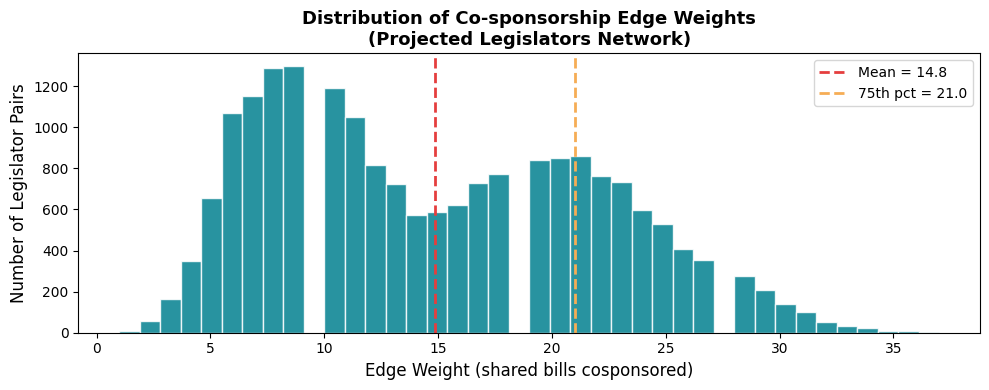

In [4]:
# Weighted projection: legislators connected by number of shared bills
W = bipartite.weighted_projected_graph(G, legislators)

edge_weights = [d["weight"] for u, v, d in W.edges(data=True)]
print(f"Projected legislators network:")
print(f"  Nodes  : {W.number_of_nodes()}")
print(f"  Edges  : {W.number_of_edges()}")
print(f"  Edge weight (shared bills):")
print(f"    Min    : {min(edge_weights)}")
print(f"    Max    : {max(edge_weights)}")
print(f"    Mean   : {np.mean(edge_weights):.2f}")
print(f"    Median : {np.median(edge_weights):.1f}")
print()

# Weight distribution
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(edge_weights, bins=40, color="#028090", edgecolor="white", alpha=0.85)
ax.axvline(np.mean(edge_weights), color="#E53E3E", linestyle="--", linewidth=2,
           label=f"Mean = {np.mean(edge_weights):.1f}")
ax.axvline(np.percentile(edge_weights, 75), color="#F6AD55", linestyle="--", linewidth=2,
           label=f"75th pct = {np.percentile(edge_weights, 75):.1f}")
ax.set_xlabel("Edge Weight (shared bills cosponsored)", fontsize=12)
ax.set_ylabel("Number of Legislator Pairs", fontsize=12)
ax.set_title("Distribution of Co-sponsorship Edge Weights\n(Projected Legislators Network)",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

### Island Method: Progressive Threshold Reduction

In [5]:
# Island method: retain only edges with weight >= threshold
thresholds = [1, 5, 10, 15, 20, 25]
results = []

for t in thresholds:
    island = nx.Graph()
    island.add_nodes_from(W.nodes(data=True))
    for u, v, d in W.edges(data=True):
        if d["weight"] >= t:
            island.add_edge(u, v, **d)
    # Remove isolated nodes
    isolated = [n for n in island.nodes() if island.degree(n) == 0]
    island.remove_nodes_from(isolated)

    n_comp = nx.number_connected_components(island)
    results.append({
        "Threshold": t,
        "Nodes retained": island.number_of_nodes(),
        "Edges retained": island.number_of_edges(),
        "Components": n_comp,
        "Network density": round(nx.density(island), 4) if island.number_of_nodes() > 1 else 0
    })
    print(f"Threshold >= {t:2d} shared bills: {island.number_of_nodes():4d} nodes, "
          f"{island.number_of_edges():5d} edges, {n_comp} components")

df_results = pd.DataFrame(results)
print()
print(df_results.to_string(index=False))

Threshold >=  1 shared bills:  200 nodes, 19900 edges, 1 components
Threshold >=  5 shared bills:  200 nodes, 19323 edges, 1 components
Threshold >= 10 shared bills:  200 nodes, 13856 edges, 1 components
Threshold >= 15 shared bills:  200 nodes,  9503 edges, 1 components
Threshold >= 20 shared bills:  196 nodes,  5949 edges, 1 components
Threshold >= 25 shared bills:  164 nodes,  2147 edges, 3 components

 Threshold  Nodes retained  Edges retained  Components  Network density
         1             200           19900           1           1.0000
         5             200           19323           1           0.9710
        10             200           13856           1           0.6963
        15             200            9503           1           0.4775
        20             196            5949           1           0.3113
        25             164            2147           3           0.1606


### Choose Threshold = 15 (Meaningful Island)

In [6]:
# Apply island method with threshold = 15
THRESHOLD = 15

island_net = nx.Graph()
island_net.add_nodes_from(W.nodes(data=True))
for u, v, d in W.edges(data=True):
    if d["weight"] >= THRESHOLD:
        island_net.add_edge(u, v, weight=d["weight"])

isolated = [n for n in island_net.nodes() if island_net.degree(n) == 0]
island_net.remove_nodes_from(isolated)

# Carry party attribute from G
for node in island_net.nodes():
    island_net.nodes[node]["party"] = G.nodes[node]["party"]

n_dem_island = sum(1 for n in island_net.nodes() if island_net.nodes[n]["party"] == "Democrat")
n_rep_island = sum(1 for n in island_net.nodes() if island_net.nodes[n]["party"] == "Republican")

print(f"Island network (threshold >= {THRESHOLD} shared bills):")
print(f"  Nodes retained : {island_net.number_of_nodes()} "
      f"({n_dem_island} Democrats, {n_rep_island} Republicans)")
print(f"  Edges retained : {island_net.number_of_edges()}")
print(f"  Density        : {nx.density(island_net):.4f}")
print(f"  Components     : {nx.number_connected_components(island_net)}")
print(f"  Avg clustering : {nx.average_clustering(island_net):.4f}")

Island network (threshold >= 15 shared bills):
  Nodes retained : 200 (110 Democrats, 90 Republicans)
  Edges retained : 9503
  Density        : 0.4775
  Components     : 1
  Avg clustering : 0.8946


## Part 4: Visualize the Reduced Island Network

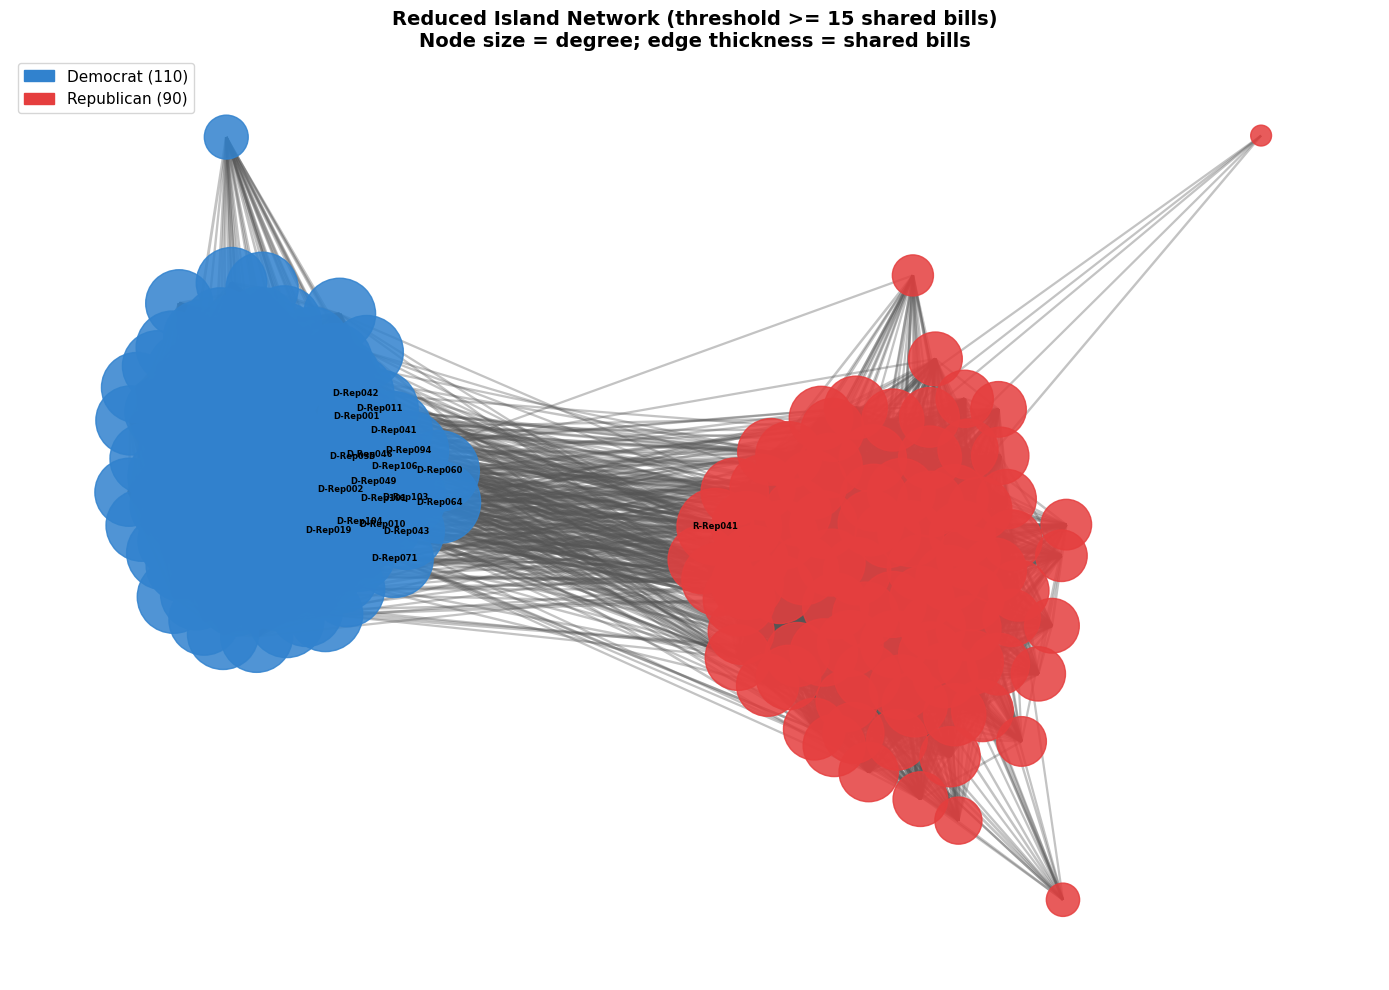

In [7]:
pos_island = nx.spring_layout(island_net, seed=42, k=0.4)

node_colors_island = ["#3182CE" if island_net.nodes[n]["party"] == "Democrat"
                       else "#E53E3E" for n in island_net.nodes()]

deg_island = dict(island_net.degree())
node_sizes = [deg_island[n] * 25 + 100 for n in island_net.nodes()]

edge_weights_island = [island_net[u][v]["weight"] for u, v in island_net.edges()]
max_ew = max(edge_weights_island)

fig, ax = plt.subplots(figsize=(14, 10))
nx.draw_networkx_nodes(island_net, pos_island, node_color=node_colors_island,
                       node_size=node_sizes, alpha=0.85, ax=ax)
nx.draw_networkx_edges(island_net, pos_island,
                       width=[w / max_ew * 4 for w in edge_weights_island],
                       alpha=0.35, edge_color="#555555", ax=ax)

# Label only high-degree nodes
top_nodes = sorted(deg_island.items(), key=lambda x: -x[1])[:20]
top_labels = {n: n for n, _ in top_nodes}
nx.draw_networkx_labels(island_net, pos_island, labels=top_labels,
                        font_size=6, font_weight="bold", ax=ax)

dem_patch = mpatches.Patch(color="#3182CE", label=f"Democrat ({n_dem_island})")
rep_patch = mpatches.Patch(color="#E53E3E", label=f"Republican ({n_rep_island})")
ax.legend(handles=[dem_patch, rep_patch], fontsize=11, loc="upper left")
ax.set_title(f"Reduced Island Network (threshold >= {THRESHOLD} shared bills)\n"
             f"Node size = degree; edge thickness = shared bills",
             fontsize=14, fontweight="bold")
ax.axis("off")
plt.tight_layout()
plt.show()

## Part 5: Inferences about Legislators (Group 1)

In [8]:
# Centrality analysis on island network
deg_c = nx.degree_centrality(island_net)
btw_c = nx.betweenness_centrality(island_net, weight="weight")
eig_c = nx.eigenvector_centrality(island_net, max_iter=1000, weight="weight")

df_leg = pd.DataFrame({
    "Party": {n: island_net.nodes[n]["party"] for n in island_net.nodes()},
    "Degree": dict(island_net.degree()),
    "Degree Centrality": deg_c,
    "Betweenness Centrality": btw_c,
    "Eigenvector Centrality": eig_c
})
df_leg = df_leg.sort_values("Eigenvector Centrality", ascending=False)

print("Top 15 most central legislators (by eigenvector centrality):")
print(df_leg.head(15).round(4).to_string())
print()

# Party breakdown in island
print("Party composition in island network:")
print(df_leg["Party"].value_counts())
print()

# Compare centrality by party
print("Mean centrality by party:")
print(df_leg.groupby("Party")[["Degree Centrality","Betweenness Centrality","Eigenvector Centrality"]].mean().round(4))

Top 15 most central legislators (by eigenvector centrality):
             Party  Degree  Degree Centrality  Betweenness Centrality  Eigenvector Centrality
D-Rep011  Democrat     121             0.6080                  0.0002                  0.1183
D-Rep094  Democrat     127             0.6382                  0.0039                  0.1161
D-Rep049  Democrat     120             0.6030                  0.0012                  0.1159
D-Rep005  Democrat     109             0.5477                  0.0000                  0.1151
D-Rep084  Democrat     112             0.5628                  0.0028                  0.1135
D-Rep106  Democrat     124             0.6231                  0.0023                  0.1134
D-Rep024  Democrat     110             0.5528                  0.0000                  0.1127
D-Rep103  Democrat     127             0.6382                  0.0077                  0.1120
D-Rep045  Democrat     109             0.5477                  0.0000                  0.1116

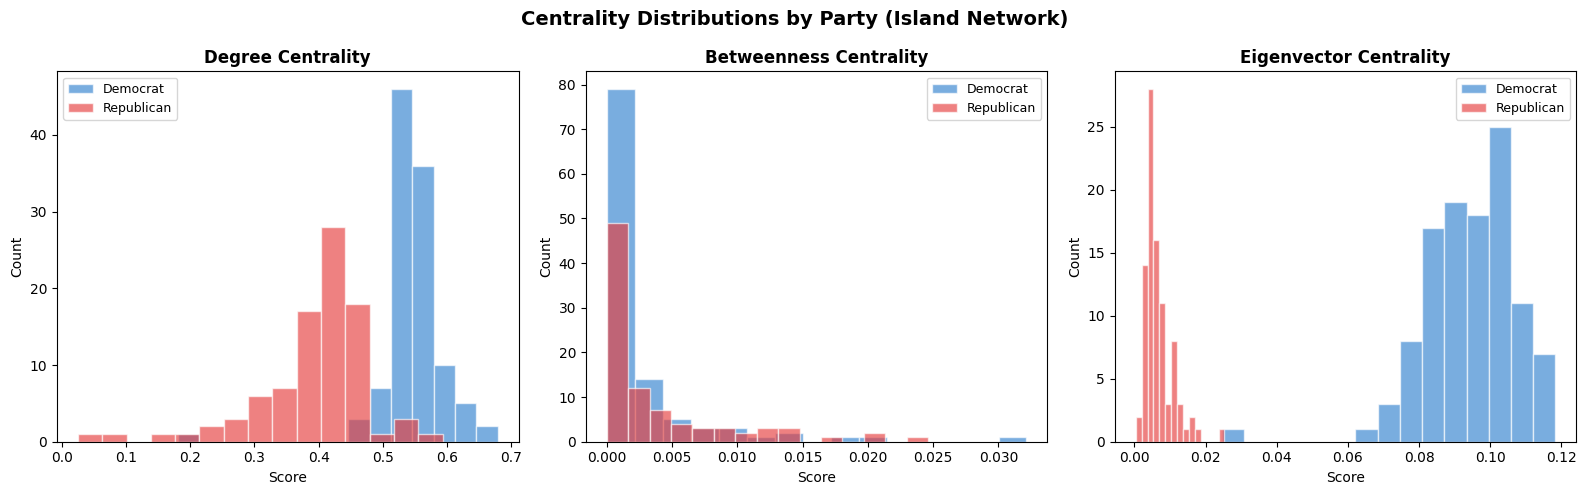

In [9]:
# Visualize centrality comparison by party
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
metrics = ["Degree Centrality", "Betweenness Centrality", "Eigenvector Centrality"]
colors = {"Democrat": "#3182CE", "Republican": "#E53E3E"}

for ax, metric in zip(axes, metrics):
    for party, color in colors.items():
        vals = df_leg[df_leg["Party"] == party][metric]
        ax.hist(vals, bins=15, alpha=0.65, color=color, label=party, edgecolor="white")
    ax.set_title(metric, fontsize=12, fontweight="bold")
    ax.set_xlabel("Score", fontsize=10)
    ax.set_ylabel("Count", fontsize=10)
    ax.legend(fontsize=9)

plt.suptitle("Centrality Distributions by Party (Island Network)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## Part 6: Inferences about Bills (Group 2)

In [10]:
# Project onto bills
B_proj = bipartite.weighted_projected_graph(G, bills)

# Bill stats
bill_info = []
for bill in bills:
    domain = G.nodes[bill]["domain"]
    n_cosponsor = G.degree(bill)
    n_dem_cos = sum(1 for leg in G.neighbors(bill) if G.nodes[leg]["party"] == "Democrat")
    n_rep_cos = sum(1 for leg in G.neighbors(bill) if G.nodes[leg]["party"] == "Republican")
    bill_info.append({
        "Bill": bill,
        "Domain": domain,
        "Total Cosponsors": n_cosponsor,
        "Democrat Cosponsors": n_dem_cos,
        "Republican Cosponsors": n_rep_cos,
        "Bipartisan Score": round(min(n_dem_cos, n_rep_cos) / max(n_dem_cos, n_rep_cos, 1), 3)
    })

df_bills = pd.DataFrame(bill_info).sort_values("Total Cosponsors", ascending=False)

print("Top 15 most cosponsored bills:")
print(df_bills.head(15).to_string(index=False))
print()
print("Average cosponsors by policy domain:")
print(df_bills.groupby("Domain")["Total Cosponsors"].agg(["mean","count"]).round(2))

Top 15 most cosponsored bills:
       Bill      Domain  Total Cosponsors  Democrat Cosponsors  Republican Cosponsors  Bipartisan Score
Bill119_EDU   Education                85                   71                     14             0.197
Bill077_HEA  Healthcare                83                   69                     14             0.203
Bill083_HEA  Healthcare                82                   68                     14             0.206
Bill099_HEA  Healthcare                81                   66                     15             0.227
Bill017_EDU   Education                81                   70                     11             0.157
Bill127_ENV Environment                81                   68                     13             0.191
Bill002_ENV Environment                80                   71                      9             0.127
Bill006_HEA  Healthcare                79                   63                     16             0.254
Bill128_HEA  Healthcare          

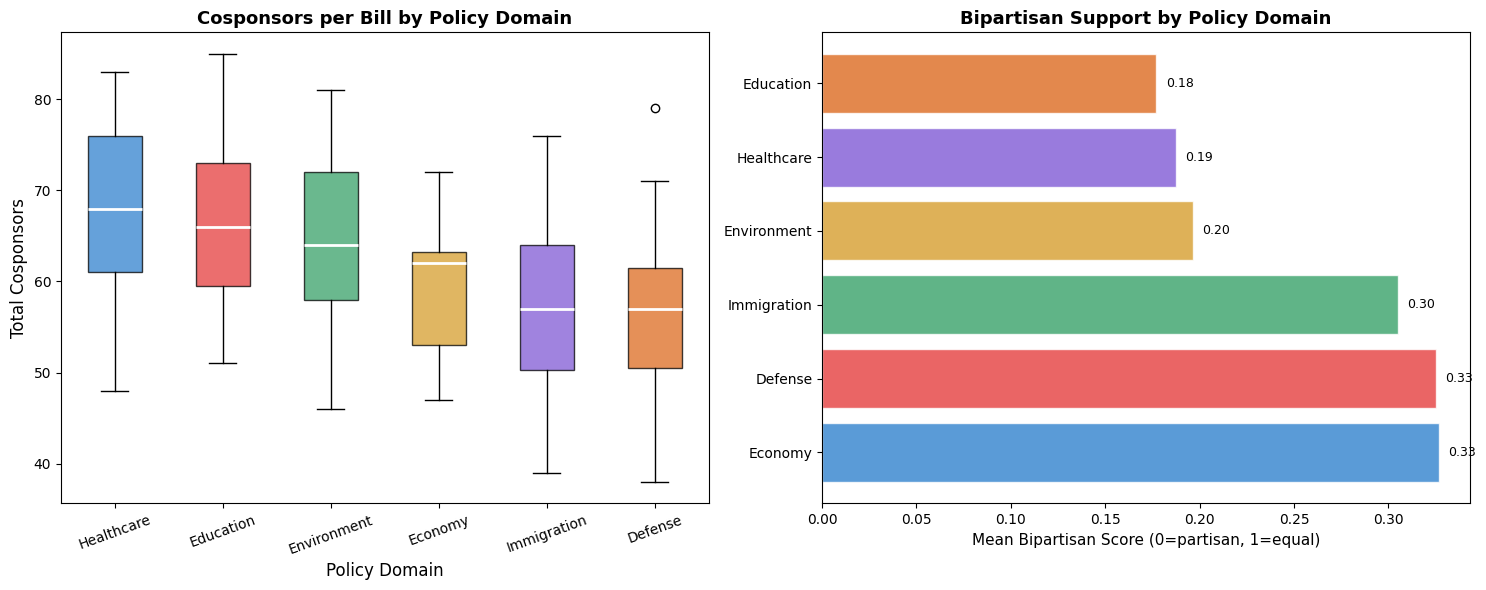

In [11]:
# Visualize bill analysis
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Cosponsors by domain (boxplot)
domains_order = df_bills.groupby("Domain")["Total Cosponsors"].mean().sort_values(ascending=False).index
data_by_domain = [df_bills[df_bills["Domain"] == d]["Total Cosponsors"].values for d in domains_order]

bp = axes[0].boxplot(data_by_domain, labels=domains_order, patch_artist=True,
                     medianprops=dict(color="white", linewidth=2))
colors_box = ["#3182CE","#E53E3E","#38A169","#D69E2E","#805AD5","#DD6B20"]
for patch, color in zip(bp["boxes"], colors_box):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)
axes[0].set_xlabel("Policy Domain", fontsize=12)
axes[0].set_ylabel("Total Cosponsors", fontsize=12)
axes[0].set_title("Cosponsors per Bill by Policy Domain", fontsize=13, fontweight="bold")
axes[0].tick_params(axis="x", rotation=20)

# Bipartisan score by domain
domain_bipartisan = df_bills.groupby("Domain")["Bipartisan Score"].mean().sort_values(ascending=False)
axes[1].barh(domain_bipartisan.index, domain_bipartisan.values,
             color=colors_box[:len(domain_bipartisan)], alpha=0.8, edgecolor="white")
axes[1].set_xlabel("Mean Bipartisan Score (0=partisan, 1=equal)", fontsize=11)
axes[1].set_title("Bipartisan Support by Policy Domain", fontsize=13, fontweight="bold")
for i, (idx, val) in enumerate(domain_bipartisan.items()):
    axes[1].text(val + 0.005, i, f"{val:.2f}", va="center", fontsize=9)

plt.tight_layout()
plt.show()

## Part 7: Findings and Interpretation

### Legislators (Node Group 1) Inferences

**Network density and the island method.** The projected legislators network contains 200 legislators and 19,900 edges, with shared-bill weights ranging from 1 to 37. Applying the island method progressively reduces the number of edges and network density. At a threshold of 15 shared bills, the reduced network retains all 200 legislators and 9,503 edges, with a density of 0.4775, an average clustering coefficient of 0.8946, and one connected component. At a threshold of 25, the network becomes more fragmented, retaining 164 legislators, 2,147 edges, and three connected components. These results demonstrate how increasing the threshold isolates stronger cosponsorship relationships and reduces network connectivity.

**Core cosponsors and peripheral members.** Degree centrality identifies legislators with many connections in the reduced network, while eigenvector centrality identifies legislators connected to other highly central legislators. The mean degree centrality is 0.5468 for Democrats and 0.3929 for Republicans. The mean eigenvector centrality is 0.0942 for Democrats and 0.0066 for Republicans. The 15 highest-ranked legislators by eigenvector centrality are all Democrats in this synthetic dataset. These results indicate that Democratic legislators occupy more prominent positions according to these centrality measures in the selected network.

**Betweenness centrality and potential brokers.** Mean betweenness centrality is 0.0025 for Democrats and 0.0038 for Republicans. The highest-ranked legislator by betweenness centrality is D-Rep060, with a score of 0.0322, followed by R-Rep076, with a score of 0.0246. These legislators may occupy positions that connect different parts of the network. However, the centrality results alone do not establish that they are moderates or that removing them would disconnect the two political parties.

### Bills (Node Group 2) Inferences

**Cosponsorship volume by policy domain.** Healthcare bills have the highest average number of cosponsors, at 67.54, followed by Education at 66.04 and Environment at 65.19. Defense bills average 56.16 cosponsors, Economy bills 59.60, and Immigration bills 57.72. In this synthetic dataset, healthcare, education, and environment bills generally attract more cosponsors than defense, economy, and immigration bills.

**Bipartisan support by policy domain.** The mean bipartisan scores are 0.327 for Economy, 0.325 for Defense, 0.305 for Immigration, 0.197 for Environment, 0.187 for Healthcare, and 0.177 for Education. Economy has the highest average bipartisan score, closely followed by Defense. Education has the lowest average score, followed by Healthcare and Environment. These findings suggest that the balance between Democratic and Republican cosponsors varies across policy domains in the generated dataset.

**Most cosponsored bills.** Bill119_EDU has the highest number of cosponsors, with 85 legislators, including 71 Democrats and 14 Republicans. Healthcare and Education bills feature prominently among the most cosponsored bills. However, a high total number of cosponsors does not necessarily indicate strong bipartisan support, because the party composition of those cosponsors must also be considered.

**Limitations of the bill projection.** The notebook constructs a weighted projection of bills based on shared legislators and summarizes bill cosponsorship by policy domain. However, it does not apply a threshold-based island analysis to the bill projection or quantitatively test whether bill clusters correspond to policy domains. Therefore, further analysis would be needed to establish whether the projected bill network forms distinct policy-domain clusters.

### **Conclusion**

The analysis demonstrates how bipartite network projection and the island method can be used to examine cosponsorship relationships in a synthetic legislative dataset. The legislators' projection is initially fully connected, and increasing the shared-bill threshold reduces its density and eventually produces multiple connected components. At the selected threshold of 15, the network remains connected but is substantially sparser than the original projection. Centrality measures show differences between Democrats and Republicans in network position, while bill-level statistics reveal variation in cosponsorship volume and bipartisan balance across policy domains. Because the data are synthetically generated, these findings illustrate network-analysis techniques rather than establish empirical conclusions about the actual U.S. Congress.

## References

Fowler, J. H. (2006). Connecting the Congress: A study of cosponsorship networks. *Political Analysis*, *14*(4), 456-487. https://doi.org/10.1093/pan/mpl002

Kirkland, J. H. (2011). The relational determinants of legislative outcomes. *American Political Science Review*, *105*(3), 407-423. https://doi.org/10.1017/S0003055411000189

Latapy, M., Magnien, C., & Del Vecchio, N. (2008). Basic notions for the analysis of large two-mode networks. *Social Networks*, *30*(1), 31-48. https://doi.org/10.1016/j.socnet.2007.04.006